# Лабораторная 4. Многослойный перцептрон для решения задачи регрессии

**Задание 11.** Реализуйте программно восстановление функциональной зависимости
с помощью многослойного перцептрона с одним и двумя слоями и количеством
скрытых узлов в каждом из слоёв от одного до трёх. Для этого

а) в качестве распознаваемых функциональных зависимостей используйте следующие:
$y = \cos(2\pi x)$, $y = 5x^3 + x^2 + 5$, $y = x\sin(2\pi x)$, $x \in [0, 1]$;

б) сгенерируйте выборку, моделируя ошибку измерения как нормально
распределённую случайную величину, и проведите процедуру кросс-валидации для
определения наилучшего для распознавания количества слоёв и скрытых узлов в них.

## 1. Теория

### Данные

$x$ берётся равномерно на $[0, 1]$, $y = f(x) + \varepsilon$, ошибка измерения
нормальна, $\varepsilon \sim \mathrm{N}(0, \sigma^2)$, где $\sigma$ равна $10\%$
размаха $f$ на $[0, 1]$. Обучающая выборка 50 точек, на ней проводится
кросс-валидация. Тестовая выборка 500 точек нужна только для проверки
выбранной модели.

### Многослойный перцептрон

Узел вычисляет взвешенную сумму выходов предыдущего слоя и функцию активации:

$$a_j = \sum_i w_{ij} z_i + b_j, \qquad z_j = h(a_j).$$

В скрытых узлах $h = \tanh$, выходной узел линеен: $\tilde f(w, x) = a_{\text{вых}}$.
Скрытых слоёв один или два, в каждом от одного до трёх узлов.

### Обратное распространение ошибки

Функция ошибки на выборке из $N$ точек

$$E(w) = \frac1N\sum_{n=1}^{N} E_n(w), \qquad
E_n(w) = \frac12\bigl(\tilde f(w, x_n) - y_n\bigr)^2 ,$$

множитель $1/N$ делает шаг обучения независимым от размера выборки. Для точки
$x_n$ величины $\delta_j = \partial E_n / \partial a_j$ находятся от выхода к
входу:

$$\delta_{\text{вых}} = \tilde f(w, x_n) - y_n, \qquad
\delta_j = h'(a_j)\sum_k w_{jk}\,\delta_k, \qquad h'(a_j) = 1 - z_j^2,$$

где сумма идёт по узлам следующего слоя, и

$$\frac{\partial E_n}{\partial w_{ij}} = \delta_j z_i, \qquad
\frac{\partial E_n}{\partial b_j} = \delta_j .$$

### Обучение

Этап обучения: начальные веса берутся случайно, затем делается $K$ шагов
градиентного спуска

$$w \leftarrow w - \eta\,\nabla E(w).$$

Выполняется $T$ этапов из разных начальных весов, результатом считается этап с
наименьшей ошибкой $E$. Перед обучением $x$ и $y$ приводятся к нулевому среднему
и единичной дисперсии: при больших $|a|$ производная $1 - \tanh^2 a$ близка к
нулю, и веса почти не меняются.

### Кросс-валидация

Обучающая выборка случайно делится на $F$ частей. Сеть $F$ раз обучается на
$F - 1$ частях и проверяется на оставшейся, ошибка кросс-валидации это среднее
RMSE по $F$ проверкам. Наилучшей считается архитектура с наименьшей ошибкой
кросс-валидации, она обучается на всей обучающей выборке и проверяется на
тестовой.

### Мера ошибки

$$\mathrm{RMSE} = \sqrt{\frac1n \sum_{k=1}^{n}\bigl(\tilde f(w, x_k) - y_k\bigr)^2}.$$

### Что перебирается

| Параметр | Значения |
|---|---|
| скрытые слои | $(h_1)$ или $(h_1, h_2)$, $h_1, h_2 \in \{1, 2, 3\}$, всего 12 архитектур |
| функция $f$ | $\cos(2\pi x)$, $5x^3 + x^2 + 5$, $x\sin(2\pi x)$ |
| коэффициент обучения $\eta$ | 0.1 |
| шагов градиентного спуска $K$ | 20000 |
| этапов обучения $T$ | 3 |
| частей кросс-валидации $F$ | 5 |

## 2. Данные

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110

FUNCS = {
    'cos(2 pi x)': lambda x: np.cos(2 * np.pi * x),
    '5x^3 + x^2 + 5': lambda x: 5 * x ** 3 + x ** 2 + 5,
    'x sin(2 pi x)': lambda x: x * np.sin(2 * np.pi * x),
}
N_TRAIN, N_TEST = 50, 500


def noise_sigma(f):
    # 10% размаха функции на [0, 1]
    grid = np.linspace(0, 1, 1000)
    return 0.1 * (f(grid).max() - f(grid).min())


def make_sample(f, n, rng):
    x = rng.uniform(0.0, 1.0, n)
    return x, f(x) + rng.normal(0.0, noise_sigma(f), n)


SAMPLES = {}
for name, f in FUNCS.items():
    rng = np.random.default_rng(20260905)
    x_tr, y_tr = make_sample(f, N_TRAIN, rng)
    x_te, y_te = make_sample(f, N_TEST, rng)
    SAMPLES[name] = (x_tr, y_tr, x_te, y_te)

print(pd.DataFrame({'sigma': [noise_sigma(f) for f in FUNCS.values()]},
                   index=list(FUNCS)).round(4).to_string())

                 sigma
cos(2 pi x)     0.2000
5x^3 + x^2 + 5  0.6000
x sin(2 pi x)   0.1056


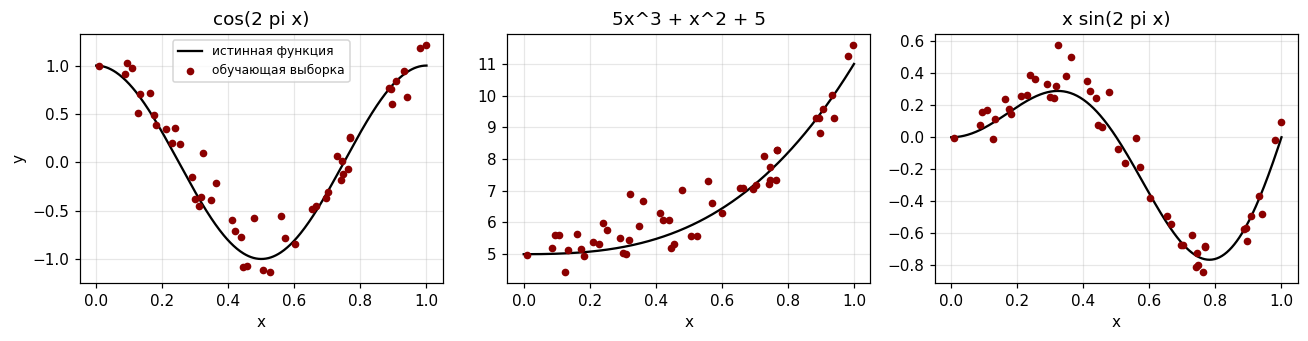

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
grid = np.linspace(0, 1, 400)
for ax, (name, f) in zip(axes, FUNCS.items()):
    x_tr, y_tr, _, _ = SAMPLES[name]
    ax.plot(grid, f(grid), color='black', label='истинная функция')
    ax.scatter(x_tr, y_tr, color='darkred', s=16, zorder=3, label='обучающая выборка')
    ax.set_title(name); ax.set_xlabel('x'); ax.grid(alpha=0.3)
axes[0].set_ylabel('y'); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Многослойный перцептрон и его обучение

In [3]:
class MLP:
    # Скрытые слои с tanh, линейный выход. W[l][j, i] это вес дуги из узла i
    # в узел j следующего слоя. Точки выборки идут столбцами матриц, поэтому
    # формулы из теории считаются сразу для всех точек.

    def __init__(self, sizes, rng):
        # начальные веса случайны, дисперсия 1 / (число входов узла)
        self.W = [rng.normal(0, np.sqrt(1.0 / m), (k, m)) for m, k in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(k) for k in sizes[1:]]

    def forward(self, x):
        # прямое распространение; возвращает выход и z всех слоёв
        z = x[None, :]  # вход это строка, столбец n соответствует точке x_n
        zs = [z]
        for l in range(len(self.W)):
            a = self.W[l] @ z + self.b[l][:, None]  # b[:, None] прибавляется к каждому столбцу
            z = a if l == len(self.W) - 1 else np.tanh(a)
            zs.append(z)
        return z[0], zs

    def gradients(self, x, y):
        # обратное распространение ошибки для E = (1/N) * сумма E_n
        out, zs = self.forward(x)
        delta = (out - y)[None, :] / len(y)  # delta выхода, 1/N из формулы E
        gW, gb = [None] * len(self.W), [None] * len(self.b)
        for l in reversed(range(len(self.W))):
            # столбец n матрицы delta это delta_j для точки x_n, умножение на
            # zs[l].T складывает delta_j * z_i по всем точкам
            gW[l] = delta @ zs[l].T
            gb[l] = delta.sum(axis=1)
            if l > 0:
                delta = (self.W[l].T @ delta) * (1 - zs[l] ** 2)  # delta_j = h'(a_j) сумма w_jk delta_k
        return gW, gb

    def error(self, x, y):
        out, _ = self.forward(x)
        return float(np.mean((out - y) ** 2) / 2)

In [4]:
ETA, K, T = 0.1, 20000, 3


def train_stage(model, x, y):
    # этап обучения: K шагов градиентного спуска
    for _ in range(K):
        gW, gb = model.gradients(x, y)
        for l in range(len(model.W)):
            model.W[l] -= ETA * gW[l]
            model.b[l] -= ETA * gb[l]
    return model


def fit(x, y, hidden, rng):
    # T этапов из разных начальных весов, берётся сеть с наименьшей ошибкой
    models = [train_stage(MLP([1] + list(hidden) + [1], rng), x, y) for _ in range(T)]
    return min(models, key=lambda m: m.error(x, y))


def fit_scaled(x, y, hidden, rng):
    # обучение на нормированных x и y; возвращается функция предсказания,
    # которая нормирует вход и переводит выход сети обратно в единицы y
    mx, sx, my, sy = x.mean(), x.std(), y.mean(), y.std()
    model = fit((x - mx) / sx, (y - my) / sy, hidden, rng)
    return lambda t: model.forward((t - mx) / sx)[0] * sy + my


def rmse(pred, y):
    return float(np.sqrt(np.mean((pred - y) ** 2)))

## 4. Кросс-валидация по архитектурам

In [5]:
ARCHS = [(h,) for h in (1, 2, 3)] + [(h1, h2) for h1 in (1, 2, 3) for h2 in (1, 2, 3)]
F = 5


def cv_error(x, y, hidden, rng):
    # перемешанные номера точек делятся на F почти равных частей
    parts = np.array_split(rng.permutation(len(x)), F)
    errs = []
    for i in range(F):
        tr = np.concatenate([parts[j] for j in range(F) if j != i])
        predict = fit_scaled(x[tr], y[tr], hidden, rng)
        errs.append(rmse(predict(x[parts[i]]), y[parts[i]]))
    return float(np.mean(errs))


rows = []
for name in FUNCS:
    x_tr, y_tr, _, _ = SAMPLES[name]
    for hidden in ARCHS:
        # одинаковый генератор для всех архитектур: разбиение на части одно и то же
        cv = cv_error(x_tr, y_tr, hidden, np.random.default_rng(7))
        rows.append(dict(func=name, layers=len(hidden), hidden=str(hidden), cv=cv))
res = pd.DataFrame(rows)
res.to_csv('results.csv', index=False)

# строки в порядке списка ARCHS, столбцы в порядке FUNCS
table = res.pivot_table(index='hidden', columns='func', values='cv')
table = table.loc[[str(a) for a in ARCHS], list(FUNCS)]
print('RMSE кросс-валидации:')
print(table.round(4).to_string())

RMSE кросс-валидации:
func    cos(2 pi x)  5x^3 + x^2 + 5  x sin(2 pi x)
hidden                                            
(1,)         0.6135          0.5205         0.1879
(2,)         0.1734          0.5104         0.1345
(3,)         0.1742          0.5020         0.0891
(1, 1)       0.6139          0.5626         0.1883
(1, 2)       0.1753          0.4881         0.1371
(1, 3)       0.1722          0.4976         0.1060
(2, 1)       0.1763          0.5038         0.1560
(2, 2)       0.1729          0.5572         0.0953
(2, 3)       0.1822          0.4869         0.0985
(3, 1)       0.1783          0.5100         0.0903
(3, 2)       0.1838          0.4973         0.0908
(3, 3)       0.1762          0.5013         0.0915


## 5. Наилучшее количество слоёв и узлов

In [6]:
BY_NAME = {str(a): a for a in ARCHS}  # кортеж слоёв по его записи в таблице

rows, predictors = [], {}
for name in FUNCS:
    x_tr, y_tr, x_te, y_te = SAMPLES[name]
    s = res[res.func == name]
    best = s.loc[s.cv.idxmin()]  # строка с наименьшей ошибкой кросс-валидации
    hidden = BY_NAME[best.hidden]
    predictors[name] = fit_scaled(x_tr, y_tr, hidden, np.random.default_rng(7))
    rows.append(dict(func=name, layers=len(hidden), hidden=best.hidden, cv=best.cv,
                     test=rmse(predictors[name](x_te), y_te), sigma=noise_sigma(FUNCS[name])))
chosen = pd.DataFrame(rows)
print(chosen.round(4).to_string(index=False))

          func  layers hidden     cv   test  sigma
   cos(2 pi x)       2 (1, 3) 0.1722 0.2196 0.2000
5x^3 + x^2 + 5       2 (2, 3) 0.4869 0.6623 0.6000
 x sin(2 pi x)       1   (3,) 0.0891 0.1169 0.1056


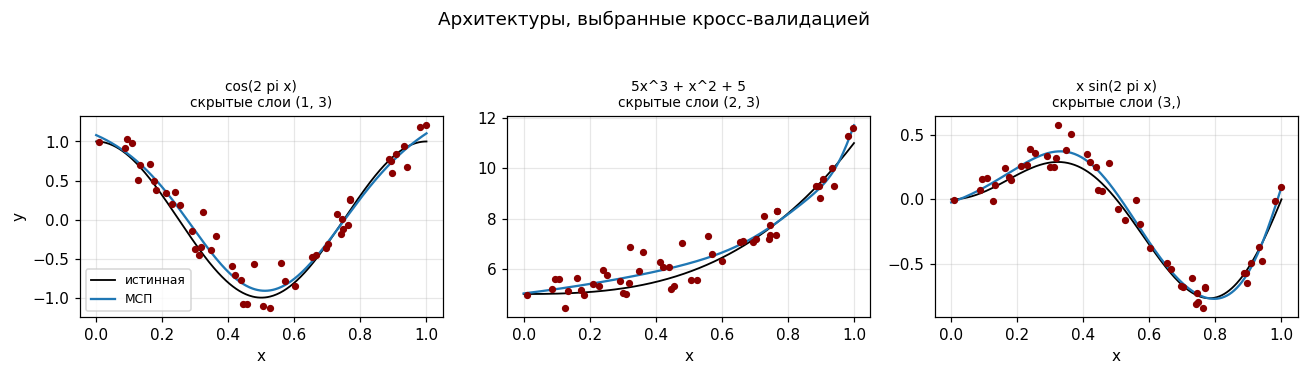

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
grid = np.linspace(0, 1, 400)
for ax, row in zip(axes, chosen.itertuples()):
    x_tr, y_tr, _, _ = SAMPLES[row.func]
    ax.plot(grid, FUNCS[row.func](grid), color='black', lw=1.2, label='истинная')
    ax.plot(grid, predictors[row.func](grid), color='tab:blue', label='МСП')
    ax.scatter(x_tr, y_tr, color='darkred', s=14, zorder=3)
    ax.set_title(f'{row.func}\nскрытые слои {row.hidden}', fontsize=9)
    ax.set_xlabel('x'); ax.grid(alpha=0.3)
axes[0].set_ylabel('y'); axes[0].legend(fontsize=8)
fig.suptitle('Архитектуры, выбранные кросс-валидацией', y=1.05)
plt.tight_layout()
plt.show()